In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)


In [2]:
x_house, y_house = 2, 9
w_house, b_house = 3, 2
prediction = w_house * x_house + b_house

print(f"Prediction: {prediction}, target: {y_house}")
print(f"Error: {prediction - y_house}")

Prediction: 8, target: 9
Error: -1


Errors:  [-1.0, -2.0, -3.0]
Squared errors:  [1.0, 4.0, 9.0]
MSE: 4.6667


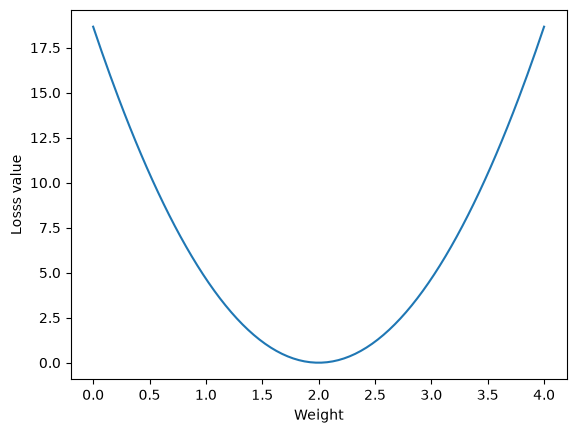

In [3]:
x_clean = torch.tensor([1., 2, 3])
y_clean = torch.tensor([3., 5, 7])
errors = 1. * x_clean + 1. - y_clean
print("Errors: ", errors.tolist())
print("Squared errors: ", errors.square().tolist())
print(f"MSE: {errors.square().mean().item():.4f}")
weights = torch.linspace(0,4, 161)
losses = torch.stack([
    ((w*x_clean + 1. - y_clean)**2).mean() for w in weights
])
plt.plot(weights, losses)
plt.xlabel("Weight")
plt.ylabel('Losss value')

plt.show()



Simple derivative: -4.000000, numeric: -4.000000
Chain derivative: -16.0000, numeric: -16.0000


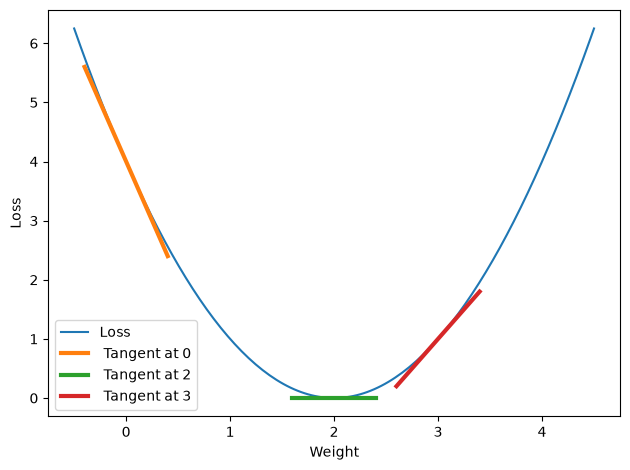

In [5]:
def single_loss(w):
    return (w - 2)**2

w0, h = 0., 0.001
numeric = (single_loss(w0 + h) - single_loss(w0 - h)) / (2 * h)

print(f"Simple derivative: {2 * (w0 - 2):.6f}, numeric: {numeric:.6f}")
chain_gradient = 2 * (1*2 - 6)*2.0
chain_numeric = (((1+h) * 2 - 6)**2 - ((1-h)*2 - 6)**2) / (2*h)

print(f"Chain derivative: {chain_gradient:.4f}, numeric: {chain_numeric:.4f}")

grid = torch.linspace(-0.5, 4.5, 150)
plt.plot(grid, (grid - 2)**2, label = 'Loss')
for point in [0.0, 2.0, 3]:
    local = torch.linspace(point - 0.4, point + 0.4, 20)
    tangent = single_loss(point) + 2*(point - 2)*(local - point)
    plt.plot(local, tangent, linewidth = 3, label = f" Tangent at {point:g}")

plt.xlabel("Weight")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
w_hand = 0.0
hand_rows = []
print("Step   |  old w   | gradient   |  new w  |   new loss")
for step in range(1, 10):
    gradient = 2 * (w_hand - 2)
    new_w = w_hand - 0.25 * gradient
    row = (step, w_hand, gradient, new_w, single_loss(new_w))
    hand_rows.append(row)
    print(f"{step}      |  {w_hand:.3f}   |  {gradient:.2f}     | " 
          f"   {new_w:.2f}   |  {single_loss(new_w):.4f}")
    w_hand = new_w

Step   |  old w   | gradient   |  new w  |   new loss
1      |  0.000   |  -4.00     |    1.00   |  1.0000
2      |  1.000   |  -2.00     |    1.50   |  0.2500
3      |  1.500   |  -1.00     |    1.75   |  0.0625
4      |  1.750   |  -0.50     |    1.88   |  0.0156
5      |  1.875   |  -0.25     |    1.94   |  0.0039
6      |  1.938   |  -0.12     |    1.97   |  0.0010
7      |  1.969   |  -0.06     |    1.98   |  0.0002
8      |  1.984   |  -0.03     |    1.99   |  0.0001
9      |  1.992   |  -0.02     |    2.00   |  0.0000


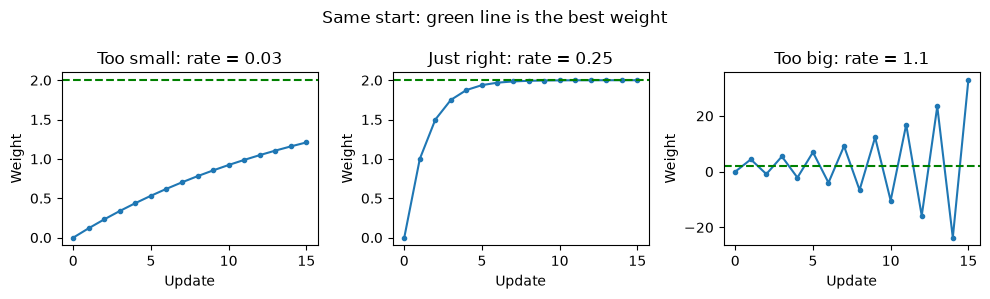

In [15]:
fig, axes = plt.subplots(1, 3, figsize = (10,3))
for ax, rate, name in zip(axes, [0.03, 0.25, 1.1], ['Too small', 'Just right', 'Too big']):
    weight, path = 0.0, [0.0]
    for _ in range(15):
        weight -= rate * (2 * (weight - 2))
        path.append(weight)
    ax.plot(range(16), path, 'o-', markersize = 3)
    ax.axhline(2, color = 'green', linestyle = '--')
    ax.set(title = f"{name}: rate = {rate}", xlabel = 'Update', ylabel = 'Weight')
fig.suptitle("Same start: green line is the best weight")
fig.tight_layout()
plt.show()

## Let's create a sample data

Input shape:  torch.Size([80]) Target shape:  torch.Size([80])


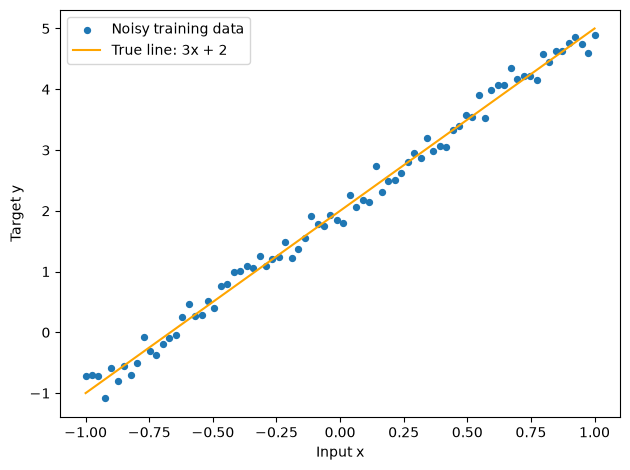

In [18]:
torch.manual_seed(42)
x = torch.linspace(-1, 1, 80)
y = 3 * x + 2 + 0.15 * torch.randn_like(x)
def predict(x, w, b):
    return w*x + b

def mse(prediction, target):
    return (prediction - target).square().mean()

def manual_gradients(x, prediction, target):
    error = prediction - target
    return 2 * (error * x).mean(), 2 * error.mean()

print("Input shape: ", x.shape, "Target shape: ", y.shape)
plt.scatter(x, y, s = 18, label = 'Noisy training data')
plt.plot(x, 3 * x + 2, color = 'orange', label = 'True line: 3x + 2')
plt.xlabel("Input x")
plt.ylabel("Target y")
plt.legend()
plt.tight_layout()
plt.show()

Before update   0:  loss: 7.130057
Before update  50:  loss: 0.027249
Before update 100:  loss: 0.024672
Before update 150:  loss: 0.024670
After 200 updates: loss = 0.024670
Manual: w =2.9948, b = 2.0100


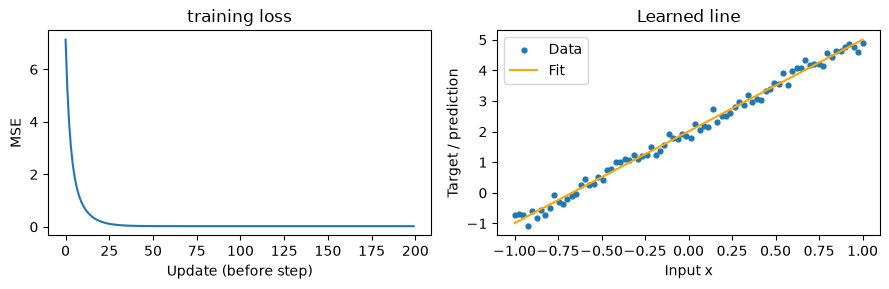

In [20]:
w_manual, b_manual = torch.tensor(0.0), torch.tensor(0.0)
learning_rate, steps = 0.1, 200
manual_history = []
for step in range(steps):
    prediction = predict(x, w_manual, b_manual)
    loss = mse(prediction, y)
    grad_w, grad_b = manual_gradients(x, prediction, y)
    manual_history.append(loss.item())
    if step % 50 == 0:
        print(f"Before update {step:3d}:  loss: {loss.item():.6f}")
    w_manual -= learning_rate*grad_w
    b_manual -= learning_rate*grad_b

final_manual = mse(predict(x, w_manual, b_manual), y).item()
print(f"After {steps} updates: loss = {final_manual:.6f}")
print(f"Manual: w ={w_manual.item():.4f}, b = {b_manual.item():.4f}")
fig, axes = plt.subplots(1,2, figsize = (9,3))
axes[0].plot(manual_history)
axes[0].set(xlabel = 'Update (before step)', ylabel = 'MSE', title = 'training loss')
axes[1].scatter(x, y, s = 12, label = 'Data')
axes[1].plot(x, predict(x, w_manual, b_manual), color = 'orange', label = 'Fit')
axes[1].set(xlabel = 'Input x', ylabel = 'Target / prediction', title = 'Learned line')
axes[1].legend()
fig.tight_layout()
plt.show()

In [21]:
w_manual

tensor(2.9948)

In [22]:
b_manual

tensor(2.0100)

## The same training loop using autograd

In [23]:
w_auto = torch.tensor(0.0, requires_grad=True)
b_auto = torch.tensor(0.0, requires_grad=True)
prediction = predict(x, w_auto, b_auto)
loss = mse(prediction, y)
expected_w, expected_b = manual_gradients(x, prediction, y)
loss.backward()
print(f"Weight: manual= {expected_w.item():.6f}, autograd = {w_auto.grad.item():.6f}")
print(f"Bias:   manual={expected_b.item():.6f}, autograd = {b_auto.grad.item():.6f}")



Weight: manual= -2.047092, autograd = -2.047092
Bias:   manual=-4.019976, autograd = -4.019976


In [24]:
w_auto.grad.zero_()
b_auto.grad.zero_()

tensor(0.)

In [25]:
for step in range(steps):
    loss = mse(predict(x, w_auto, b_auto), y)
    loss.backward()
    with torch.no_grad():
        w_auto -= learning_rate * w_auto.grad
        b_auto -= learning_rate * b_auto.grad

    w_auto.grad.zero_()
    b_auto.grad.zero_()

print(f"Autograd: w = {w_auto.item():.4f}, b = {b_auto.item():.4f}")


Autograd: w = 2.9948, b = 2.0100


## Using the pytorch training loop

In [28]:
from torch import nn

x_column, y_column = x.reshape(-1,1), y.reshape(-1,1)
model = nn.Linear(1,1)
with torch.no_grad():
    model.weight.fill_(0.0)
    model.bias.fill_(0.0)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)
for step in range(steps):
    prediction = model(x_column)
    loss = criterion(prediction, y_column)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("method        | weight                     |  bias")
print(f"True values  | {3}                        |  {2}")
print(f"Manual       | {w_manual.item():.4f}      |  {b_manual.item():.4f}")
print(f"Autograd     |  {w_auto.item():.4f}       |  {b_auto.item():.4f}")
print(f"nn + SGD     |  {model.weight.item():.4f} |  {model.bias.item():.4f}")



method        | weight                     |  bias
True values  | 3                        |  2
Manual       | 2.9948      |  2.0100
Autograd     |  2.9948       |  2.0100
nn + SGD     |  2.9948 |  2.0100
